# Assignment 3 — Part B: DashMart — How Long Will My Order Take?
**K-Nearest Neighbours regression.** Run the notebook top to bottom in Google Colab (*Runtime → Run all*).
The first cell asks you to upload `dashmart_delivery_times_raw.csv` if it is not already in the Colab session.
Every imputer and scaler sits inside a `Pipeline`; `random_state = 42` everywhere.

In [1]:
# Setup — imports and data upload
import os, re, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, KFold
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)
RS = 42
FILE = 'dashmart_delivery_times_raw.csv'

if not os.path.exists(FILE):
    try:
        from google.colab import files
        print(f'Upload {FILE}')
        files.upload()
    except ImportError:
        raise FileNotFoundError(f'Put {FILE} next to this notebook')

## Cleaning (Q1–Q7)
### Q1 — Load as text and list the raw formats

In [2]:
# Q1 — load as text; replace every number by N to reveal the distinct formats
raw = pd.read_csv(FILE, dtype=str, keep_default_na=False)
print('Shape:', raw.shape)

def fmt(s):
    return s.str.strip().str.replace(r'\d+(?:\.\d+)?', 'N', regex=True).replace('', '<blank>')

for c in ['order_hour', 'distance_km', 'delivery_minutes']:
    f = fmt(raw[c])
    print(f'\n{c}:')
    display(pd.DataFrame({'count': f.value_counts(), 'example': raw[c].groupby(f).first()}))

Shape: (2430, 11)

order_hour:


,count,example
order_hour,,
N,1766,14
N AM,101,12 AM
N PM,250,2 PM
N:N,313,22:00



distance_km:


,count,example
distance_km,,
N,1638,0.74
N km,410,0.9 km
N m,382,210 m



delivery_minutes:


,count,example
delivery_minutes,,
-N,2,-5.0
N,2000,6.3
N min,153,14.4 min
N:N:N,275,0:06:12


**Interpretation:** each of the three columns mixes several formats (24-h numbers, "HH:00", "8 PM"; km, "km", "m"; minutes, "min", "h:mm:ss") — they must be parsed into one unit before any distance between orders means anything.

### Q2 — Store names and order hour

In [3]:
# Q2 — one spelling per store; order_hour -> integer 0–23
df = raw.copy()
NA_TOKENS = {'', 'na', 'n/a', 'nan', 'none', '?', 'null'}
df = df.apply(lambda s: s.str.strip())
df = df.mask(df.apply(lambda s: s.str.lower().isin(NA_TOKENS)))

def clean_store(s):
    if pd.isna(s):
        return np.nan
    return 'DM-' + re.split(r'[\s\-_]+', s.lower())[-1].title()
df['store'] = df['store'].map(clean_store)
print('Stores:', df['store'].value_counts(dropna=False).to_dict())

def parse_hour(v):
    if pd.isna(v):
        return np.nan
    v = v.upper().replace('.', '').strip()
    m = re.fullmatch(r'(\d{1,2})(?::\d{2})?\s*(AM|PM)', v)
    if m:                                    # 12 AM -> 0, 8 PM -> 20, 12 PM -> 12
        h = int(m[1]) % 12
        return h + 12 if m[2] == 'PM' else h
    m = re.fullmatch(r'(\d{1,2})(?::\d{2}){0,2}', v)
    return int(m[1]) % 24 if m else np.nan

raw_hour = df['order_hour'].copy()
df['order_hour'] = raw_hour.map(parse_hour).astype(float)
print('Unparsed hours:', raw_hour[df['order_hour'].isna() & raw_hour.notna()].unique())
ex = pd.DataFrame({'raw': raw_hour, 'hour': df['order_hour']}).drop_duplicates('raw')
display(ex[ex['raw'].str.contains('AM|PM|:', na=False)].sort_values('hour').head(20))
print('Hour range:', df['order_hour'].min(), '-', df['order_hour'].max())

Stores: {'DM-Nerul': 638, 'DM-Vashi': 624, 'DM-Kharghar': 595, 'DM-Panvel': 573}
Unparsed hours: []


,raw,hour
21,12 AM,0.0
76,00:00,0.0
544,1 AM,1.0
213,01:00,1.0
32,2 AM,2.0
328,3 AM,3.0
894,03:00,3.0
186,04:00,4.0
1364,4 AM,4.0
2088,5 AM,5.0


Hour range: 0.0 - 23.0


**Interpretation:** "8 PM" → 20 (add 12 to PM hours), "12 AM" → 0 (midnight) and "12 PM" → 12 (noon), handled by `hour % 12` before adding 12; "20:00" keeps the hour part. All hours now lie in 0–23.

### Q3 — Distance in kilometres

In [4]:
# Q3 — "1.4 km" -> 1.4, "850 m" -> 0.85, plain number = km
def parse_dist(v):
    if pd.isna(v):
        return np.nan
    m = re.fullmatch(r'([\d.]+)\s*(km|m)?', v.lower().strip())
    if not m:
        return np.nan
    x = float(m[1])
    return x / 1000 if m[2] == 'm' else x

raw_dist = df['distance_km'].copy()
df['distance_km'] = raw_dist.map(parse_dist)
print('Unparsed distances:', raw_dist[df['distance_km'].isna() & raw_dist.notna()].unique())
ex = pd.DataFrame({'raw': raw_dist, 'km': df['distance_km']})
display(pd.concat([ex[ex['raw'].str.contains('km', na=False)].head(2),
                   ex[ex['raw'].str.fullmatch(r'[\d.]+\s*m', na=False)].head(2),
                   ex[ex['raw'].str.fullmatch(r'[\d.]+', na=False)].head(1)]))
print(df['distance_km'].describe().round(2))

Unparsed distances:

 []


,raw,km
1,0.9 km,0.90
5,0.3 km,0.30
4,210 m,0.21
6,690 m,0.69
0,0.74,0.74


count    2430.00
mean        1.30
std         0.87
min         0.20
25%         0.65
50%         1.10
75%         1.73
max         5.00
Name: distance_km, dtype: float64


**Interpretation:** "km" must be checked before "m" (otherwise "1.4 km" would be read as metres); after conversion all distances sit in a sensible 0–4 km dark-store radius.

### Q4 — Delivery minutes and impossible values

In [5]:
# Q4 — minutes, "14.6 min", "0:14:36" -> decimal minutes
def parse_minutes(v):
    if pd.isna(v):
        return np.nan
    v = v.lower().replace('mins', '').replace('min', '').strip()
    if ':' in v:
        parts = [float(p) for p in v.split(':')]
        if len(parts) == 3:
            h, m, s = parts
            return h * 60 + m + s / 60
        m, s = parts
        return m + s / 60
    try:
        return float(v)
    except ValueError:
        return np.nan

raw_min = df['delivery_minutes'].copy()
df['delivery_minutes'] = raw_min.map(parse_minutes)
print('Unparsed:', raw_min[df['delivery_minutes'].isna() & raw_min.notna()].unique())
display(pd.DataFrame({'raw': raw_min, 'minutes': df['delivery_minutes'].round(2)})
        [raw_min.str.contains('min|:', na=False)].head(5))

impossible = (df['delivery_minutes'] <= 0) | (df['delivery_minutes'] > 120)
print(f'\nImpossible values (<= 0 or > 120 min): {impossible.sum()}')
display(pd.DataFrame({'order_id': df['order_id'], 'raw': raw_min, 'minutes': df['delivery_minutes'].round(1)})[impossible])
print('Orders between 60 and 120 min (kept):', df['delivery_minutes'].between(60, 120).sum())
n0 = len(df)
df = df[~impossible & df['delivery_minutes'].notna()].reset_index(drop=True)
print(f'Rows {n0} -> {len(df)}; largest remaining delivery: {df["delivery_minutes"].max():.1f} min')

Unparsed: []


,raw,minutes
12,14.4 min,14.4
17,18.4 min,18.4
28,0:06:12,6.2
32,13.8 min,13.8
51,0:13:42,13.7



Impossible values (<= 0 or > 120 min): 9


,order_id,raw,minutes
512,DMO700646,-5.0,-5.0
545,DMO701295,-5.0,-5.0
623,DMO701976,0.0,0.0
733,DMO700195,1440.0,1440.0
969,DMO700756,987.5,987.5
1281,DMO701688,1440.0,1440.0
1667,DMO701526,412.0,412.0
1807,DMO701557,987.5,987.5
2389,DMO701489,1440.0,1440.0


Orders between 60 and 120 min (kept): 0
Rows 2430 -> 2421; largest remaining delivery: 34.7 min


**Rule:** a delivery must take more than 0 minutes and no more than 120 minutes (a 15-minute dark-store service; the valid values stop well below that). **Why drop, not fix:** these are cancelled-and-reopened orders — the number is not a mistyped delivery time we could correct, it measures a different event. There is no true delivery time to recover, and imputing one would invent a target; leaving them in would drag the KNN averages for their neighbours by hours.

### Q5 — Raining, order value, rider experience, duplicates

In [6]:
# Q5
RAIN = {'y': 1, 'yes': 1, '1': 1, 'true': 1, 'n': 0, 'no': 0, '0': 0, 'false': 0}
df['raining'] = df['raining'].str.lower().map(RAIN)
df['order_value_rs'] = pd.to_numeric(df['order_value_rs'].str.replace(r'₹|rs\.?|,|\s', '', regex=True, case=False),
                                     errors='coerce')
df['rider_experience_months'] = df['rider_experience_months'].str.lower().replace({'new joiner': '0'})
for c in ['rider_experience_months', 'store_queue', 'items', 'drop_floor']:
    conv = pd.to_numeric(df[c], errors='coerce')
    bad = df.loc[df[c].notna() & conv.isna(), c].unique()
    if len(bad):
        print(f'{c}: non-numeric -> NaN {bad}')
    df[c] = conv
print('raining:', df['raining'].value_counts(dropna=False).to_dict())

n_before = len(df)
n_dup = df.duplicated().sum()
df = df.drop_duplicates().reset_index(drop=True)
print(f'Rows before: {n_before} | exact duplicates: {n_dup} | rows after: {len(df)}')
print('order_ids still duplicated:', df['order_id'].duplicated().sum())

raining: {0: 1905, 1: 516}
Rows before: 2421 | exact duplicates: 30 | rows after: 2391
order_ids still duplicated: 0


**Interpretation:** all model columns are now numeric, "new joiner" is honestly 0 months of experience, and each order appears once.

### Q6 — Missing values and imputation plan

In [7]:
# Q6
print(df.isna().sum())
df.to_csv('dashmart_clean.csv', index=False)
print('\nSaved dashmart_clean.csv', df.shape)

order_id                    0
store                       0
order_hour                  0
distance_km                 0
items                       0
order_value_rs              0
store_queue                40
raining                     0
rider_experience_months    43
drop_floor                  0
delivery_minutes            0
dtype: int64



Saved dashmart_clean.csv (2391, 11)


**Imputation plan:** `SimpleImputer(strategy="median")` inside the pipeline for store_queue, rider_experience_months and any other gaps — median is robust to the long right tail of queue length and experience, and fitting it inside the pipeline keeps test orders out of the fill value.

### Q7 — How long do deliveries take today?

count    2391.00
mean       14.70
std         4.57
min         5.00
25%        11.50
50%        14.10
75%        17.30
max        34.70
Name: delivery_minutes, dtype: float64


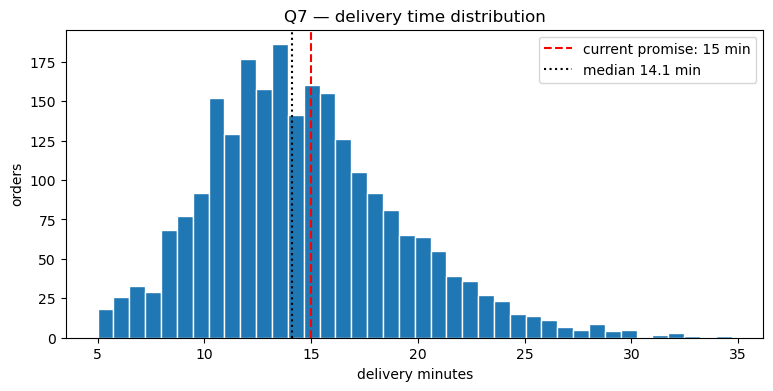

Median 14.1 min, mean 14.7 min -> the typical (median) order arrives 0.9 min earlier than the 15-minute promise, but 41.7% of orders break the promise and the slowest quarter take over 17.3 min.


In [8]:
# Q7
dm = df['delivery_minutes']
print(dm.describe().round(2))
plt.figure(figsize=(9, 4))
plt.hist(dm, bins=40, edgecolor='white')
plt.axvline(15, color='red', ls='--', label='current promise: 15 min')
plt.axvline(dm.median(), color='black', ls=':', label=f'median {dm.median():.1f} min')
plt.xlabel('delivery minutes'); plt.ylabel('orders'); plt.title('Q7 — delivery time distribution')
plt.legend(); plt.show()
gap = dm.median() - 15
print(f'Median {dm.median():.1f} min, mean {dm.mean():.1f} min -> the typical (median) order arrives '
      f'{abs(gap):.1f} min {"later" if gap > 0 else "earlier"} than the 15-minute promise, '
      f'but {(dm > 15).mean():.1%} of orders break the promise and the slowest quarter take over {dm.quantile(.75):.1f} min.')

**Interpretation:** the typical order is roughly on time, but the flat 15-minute promise sits right in the middle of a wide distribution, so about 4 in 10 orders are inevitably late — a one-size promise cannot be honest for long, rainy, high-queue orders.

## KNN regression (Q8–Q16)
### Q8 — Split and median baseline

In [9]:
# Q8 — 80/20 split and "always predict the training median" baseline
FEATS = ['distance_km', 'items', 'order_value_rs', 'store_queue', 'raining',
         'rider_experience_months', 'drop_floor', 'order_hour']
df['hour_sin'] = np.sin(2 * np.pi * df['order_hour'] / 24)    # used in Q13 (row-wise, no leakage)
df['hour_cos'] = np.cos(2 * np.pi * df['order_hour'] / 24)

train_df, test_df = train_test_split(df, test_size=0.2, random_state=RS)
y_train, y_test = train_df['delivery_minutes'], test_df['delivery_minutes']

def metrics(name, pred):
    return {'model': name, 'MAE': mean_absolute_error(y_test, pred),
            'RMSE': np.sqrt(mean_squared_error(y_test, pred)), 'R2': r2_score(y_test, pred)}

base = metrics('baseline (train median)', np.full(len(y_test), y_train.median()))
print('Train', train_df.shape, 'Test', test_df.shape)
print(pd.Series(base).drop('model').round(3))

Train (1912, 13) Test (479, 13)
MAE      3.51858
RMSE    4.525991
R2     -0.027905
dtype: object


**Interpretation:** guessing the same time for everyone is off by this many minutes on average — the number every model must beat.

### Q9 — KNN (k = 7) without scaling

In [10]:
# Q9
def fit_eval(name, model, cols):
    model.fit(train_df[cols], y_train)
    pred = model.predict(test_df[cols])
    return metrics(name, pred), pred

raw_reg = make_pipeline(SimpleImputer(strategy='median'), KNeighborsRegressor(n_neighbors=7))
res_raw, _ = fit_eval('raw KNN (k=7)', raw_reg, FEATS)
display(pd.DataFrame([base, res_raw]).set_index('model').round(3))

,MAE,RMSE,R2
model,,,
baseline (train median),3.519,4.526,-0.028
raw KNN (k=7),3.721,4.670,-0.095


**Interpretation:** R² compares the model to "always predict the average". R² near 0 means the model is no better than that single guess; a negative R² means it is actually *worse* than just quoting the average time to every customer.

### Q10 — StandardScaler vs MinMaxScaler

In [11]:
# Q10
std_reg = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), KNeighborsRegressor(n_neighbors=7))
mm_reg  = make_pipeline(SimpleImputer(strategy='median'), MinMaxScaler(), KNeighborsRegressor(n_neighbors=7))
res_std, _ = fit_eval('StandardScaler KNN (k=7)', std_reg, FEATS)
res_mm, _  = fit_eval('MinMaxScaler KNN (k=7)', mm_reg, FEATS)
display(pd.DataFrame([res_raw, res_std, res_mm]).set_index('model').round(3))

info = pd.DataFrame({'std_dev': train_df[FEATS].std(),
                     'corr_with_minutes': train_df[FEATS].corrwith(y_train)}).sort_values('std_dev', ascending=False)
display(info.round(3))
print(f'Hijacking column: {info.index[0]} (std ≈ {info["std_dev"].iloc[0]:,.0f} vs ≤ {info["std_dev"].iloc[1]:.0f} for the rest)')

,MAE,RMSE,R2
model,,,
raw KNN (k=7),3.721,4.670,-0.095
StandardScaler KNN (k=7),1.726,2.165,0.765
MinMaxScaler KNN (k=7),1.773,2.216,0.754


,std_dev,corr_with_minutes
order_value_rs,320.021,0.036
drop_floor,8.728,0.119
rider_experience_months,8.160,-0.078
order_hour,5.464,0.067
store_queue,3.472,0.329
items,2.414,0.067
distance_km,0.872,0.791
raining,0.409,0.309


Hijacking column: order_value_rs (std ≈ 320 vs ≤ 9 for the rest)


**Interpretation:** order_value_rs is measured in hundreds/thousands of rupees, so unscaled it decides on its own which orders are "similar". It is nearly useless for timing because basket value says little about the ride: whatever it does carry (bigger baskets take slightly longer to pack) is already captured by `items`. Both scalers fix the problem and give similar results.

### Q11 — MAE vs RMSE
*"MAE is the typical number of minutes our estimate is off by; RMSE is similar but punishes the occasional very wrong estimate much more, so it rises when a few customers get badly wrong ETAs."*
The target "typical error under 2.5 minutes" is an **MAE** target.

### Q12 — Choosing k with 5-fold CV

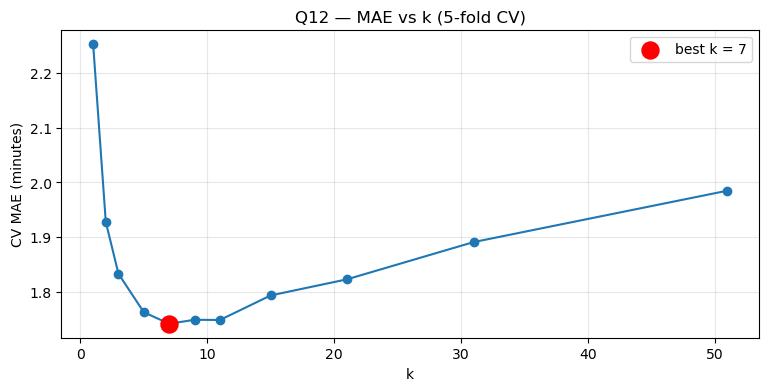

,0,1,2,3,4,5,6,7,8,9,10
k,1.000,2.000,3.000,5.000,7.000,9.000,11.000,15.000,21.000,31.000,51.000
cv_MAE,2.254,1.928,1.833,1.763,1.742,1.749,1.749,1.793,1.823,1.891,1.985


Best k = 7 (CV MAE 1.742)


In [12]:
# Q12 — CV MAE vs k (training set only)
cv = KFold(n_splits=5, shuffle=True, random_state=RS)
ks = [1, 2, 3, 5, 7, 9, 11, 15, 21, 31, 51]
cv_mae = []
for k in ks:
    pipe = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), KNeighborsRegressor(n_neighbors=k))
    cv_mae.append(-cross_val_score(pipe, train_df[FEATS], y_train, cv=cv, scoring='neg_mean_absolute_error').mean())
best_k = ks[int(np.argmin(cv_mae))]

plt.figure(figsize=(9, 4))
plt.plot(ks, cv_mae, marker='o')
plt.scatter([best_k], [min(cv_mae)], s=150, color='red', zorder=3, label=f'best k = {best_k}')
plt.xlabel('k'); plt.ylabel('CV MAE (minutes)'); plt.title('Q12 — MAE vs k (5-fold CV)')
plt.grid(alpha=.3); plt.legend(); plt.show()
display(pd.DataFrame({'k': ks, 'cv_MAE': np.round(cv_mae, 3)}).T)
print(f'Best k = {best_k} (CV MAE {min(cv_mae):.3f})')

**Interpretation:** k = 1 copies the time of one single past order, including its random luck (a slow lift, a traffic jam), so it overfits — high variance. k = 51 averages over so many orders that short and long, rainy and dry trips blur together, pulling every ETA toward the overall mean — high bias.

### Q13 — Cyclical hour encoding

In [13]:
# Q13 — hour_sin / hour_cos instead of order_hour
FEATS_LIN = FEATS
FEATS_CYC = [f for f in FEATS if f != 'order_hour'] + ['hour_sin', 'hour_cos']
late_night = test_df['order_hour'].isin([23, 0, 1]).to_numpy()

rows = []
for name, cols in [('order_hour (linear)', FEATS_LIN), ('hour_sin + hour_cos', FEATS_CYC)]:
    pipe = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), KNeighborsRegressor(n_neighbors=best_k))
    cvm = -cross_val_score(pipe, train_df[cols], y_train, cv=cv, scoring='neg_mean_absolute_error').mean()
    m, pred = fit_eval(name, pipe, cols)
    rows.append({'features': name, 'CV_MAE': cvm, 'test_MAE': m['MAE'],
                 'test_MAE_23:00-01:59': mean_absolute_error(y_test[late_night], pred[late_night])})
cyc = pd.DataFrame(rows).set_index('features')
display(cyc.round(3))
print('Test orders placed 23:00-01:59:', late_night.sum())
CHOSEN = FEATS_CYC if cyc.loc['hour_sin + hour_cos', 'CV_MAE'] <= cyc.loc['order_hour (linear)', 'CV_MAE'] else FEATS_LIN
print('Feature set carried forward (chosen by CV, not by test):', CHOSEN)

,CV_MAE,test_MAE,test_MAE_23:00-01:59
features,,,
order_hour (linear),1.742,1.726,1.692
hour_sin + hour_cos,1.794,1.772,1.761


Test orders placed 23:00-01:59: 31
Feature set carried forward (chosen by CV, not by test): ['distance_km', 'items', 'order_value_rs', 'store_queue', 'raining', 'rider_experience_months', 'drop_floor', 'order_hour']


**Interpretation (honest):** the difference is small here — very few orders are placed around midnight, and hour is only one of eight features, so the 23-vs-0 wrap-around rarely decides who the neighbours are. Cyclical encoding matters more when much of the volume sits near the wrap-around (a 24×7 service with heavy late-night ordering), when hour is a dominant driver, or for other cycles such as day-of-week or month.

### Q14 — Grid-search k and weights

In [14]:
# Q14
pipe = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), KNeighborsRegressor())
grid = GridSearchCV(pipe, {'kneighborsregressor__n_neighbors': list(range(1, 52)),
                           'kneighborsregressor__weights': ['uniform', 'distance']},
                    scoring='neg_mean_absolute_error', cv=cv)
grid.fit(train_df[CHOSEN], y_train)
best_reg = grid.best_estimator_
pred_tuned = best_reg.predict(test_df[CHOSEN])
res_tuned = metrics('tuned KNN', pred_tuned)
print('Best settings:', grid.best_params_)
print(f'CV MAE {-grid.best_score_:.3f} | test MAE {res_tuned["MAE"]:.3f} | test RMSE {res_tuned["RMSE"]:.3f} | test R² {res_tuned["R2"]:.3f}')
print('Meets the < 2.5 min MAE target?', 'YES' if res_tuned['MAE'] < 2.5 else 'NO')

Best settings: {'kneighborsregressor__n_neighbors': 8, 'kneighborsregressor__weights': 'distance'}
CV MAE 1.724 | test MAE 1.717 | test RMSE 2.150 | test R² 0.768
Meets the < 2.5 min MAE target? YES


**Interpretation:** the tuned model's typical error is shown above against the 2.5-minute target; CV and test MAE are close, so the result is not a lucky split.

### Q15 — Drop order_value_rs

In [15]:
# Q15
CHOSEN_NOVAL = [c for c in CHOSEN if c != 'order_value_rs']
grid_nv = GridSearchCV(pipe, grid.param_grid, scoring='neg_mean_absolute_error', cv=cv)
grid_nv.fit(train_df[CHOSEN_NOVAL], y_train)
pred_nv = grid_nv.best_estimator_.predict(test_df[CHOSEN_NOVAL])
res_nv = metrics('tuned KNN without order_value_rs', pred_nv)
print('Best settings:', grid_nv.best_params_, f'| CV MAE {-grid_nv.best_score_:.3f}')
display(pd.DataFrame([res_tuned, res_nv]).set_index('model').round(3))

Best settings: {'kneighborsregressor__n_neighbors': 8, 'kneighborsregressor__weights': 'distance'} | CV MAE 1.656


,MAE,RMSE,R2
model,,,
tuned KNN,1.717,2.15,0.768
tuned KNN without order_value_rs,1.699,2.15,0.768


**Interpretation:** in KNN every feature gets an equal say in the distance once scaled, so a weak feature is not ignored the way a regression coefficient near zero would be — it actively pulls in neighbours that are similar on something irrelevant. Removing a weak or redundant feature usually helps or does no harm; feature selection matters more for KNN than for most models.

### Q16 — Predicted vs actual, and where the errors are

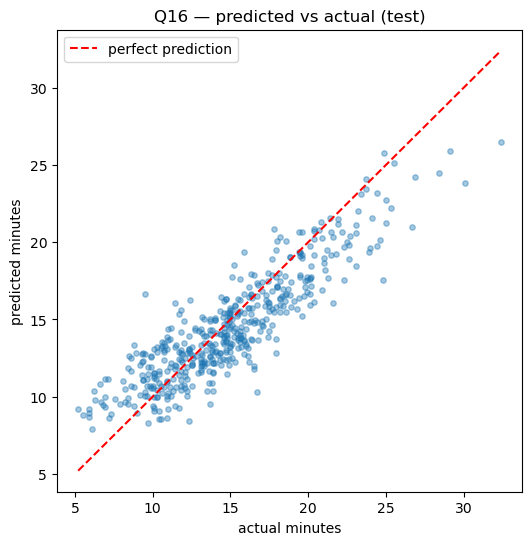

,count,MAE
rain,,
no rain,381,1.70
rain,98,1.77


,count,MAE
period,,
peak 18:00-21:59,139,1.68
rest of day,340,1.73


Ten largest errors:


,store,order_hour,distance_km,items,store_queue,raining,delivery_minutes,predicted,abs_error,rain,period
800,DM-Vashi,9.0,2.28,11,11.0,0,24.8,17.5,7.3,no rain,rest of day
2164,DM-Panvel,22.0,0.36,16,2.0,1,9.5,16.6,7.1,rain,rest of day
177,DM-Panvel,12.0,0.85,8,1.0,0,16.7,10.3,6.4,no rain,rest of day
834,DM-Vashi,17.0,3.70,10,3.0,1,30.1,23.8,6.3,rain,rest of day
303,DM-Vashi,12.0,4.84,8,1.0,1,32.4,26.5,5.9,rain,rest of day
1805,DM-Panvel,16.0,3.93,12,3.0,0,26.7,21.0,5.7,no rain,rest of day
1653,DM-Vashi,17.0,3.04,6,3.0,0,21.6,16.1,5.5,no rain,rest of day
1551,DM-Panvel,1.0,0.63,7,8.0,0,17.9,12.8,5.1,no rain,rest of day
2290,DM-Nerul,22.0,1.62,11,9.0,0,22.3,17.6,4.7,no rain,rest of day
218,DM-Vashi,0.0,0.74,7,5.0,0,16.5,11.8,4.7,no rain,rest of day


Bias by actual-time band (positive = model too high):


,abs_error,bias
actual_band,,
"(0, 10]",2.40,2.33
"(10, 15]",1.29,-0.04
"(15, 20]",1.71,-1.21
"(20, 25]",2.32,-2.22
"(25, 60]",3.90,-3.90


In [16]:
# Q16
plt.figure(figsize=(6, 6))
plt.scatter(y_test, pred_tuned, alpha=.4, s=15)
lim = [min(y_test.min(), pred_tuned.min()), max(y_test.max(), pred_tuned.max())]
plt.plot(lim, lim, 'r--', label='perfect prediction')
plt.xlabel('actual minutes'); plt.ylabel('predicted minutes'); plt.title('Q16 — predicted vs actual (test)')
plt.legend(); plt.show()

err = test_df[['store', 'order_hour', 'distance_km', 'items', 'store_queue', 'raining', 'delivery_minutes']].copy()
err['predicted'] = pred_tuned.round(1)
err['abs_error'] = (err['delivery_minutes'] - err['predicted']).abs().round(1)
err['rain'] = np.where(err['raining'] == 1, 'rain', 'no rain')
err['period'] = np.where(err['order_hour'].between(18, 21), 'peak 18:00-21:59', 'rest of day')
display(err.groupby('rain')['abs_error'].agg(['count', 'mean']).rename(columns={'mean': 'MAE'}).round(2))
display(err.groupby('period')['abs_error'].agg(['count', 'mean']).rename(columns={'mean': 'MAE'}).round(2))
print('Ten largest errors:')
display(err.nlargest(10, 'abs_error'))
err['actual_band'] = pd.cut(err['delivery_minutes'], [0, 10, 15, 20, 25, 60])
print('Bias by actual-time band (positive = model too high):')
display(err.assign(bias=err['predicted'] - err['delivery_minutes'])
           .groupby('actual_band', observed=True)[['abs_error', 'bias']].mean().round(2))

**Interpretation:** the points hug the diagonal in the 10–20 minute range; the biggest misses are at the extremes — the longest deliveries (far, 3–5 km trips) are under-predicted and the shortest are over-predicted, because averaging neighbours pulls extremes toward the middle and there are few very long past orders to copy. The rain/no-rain and peak/off-peak MAEs are close to each other (see tables), so the model handles rain and peak hours about as well as other orders — rain and queue are already features, so their neighbours are found correctly.

## The honest ETA (Q17–Q21)
### Q17 — Safety buffer

In [17]:
# Q17
yv = y_test.to_numpy()
buf = pd.DataFrame({'buffer_min': [0, 2, 3, 4, 5]})
buf['late_share'] = [(yv > pred_tuned + b).mean() for b in buf['buffer_min']]
display(buf.assign(late_share=buf['late_share'].map('{:.1%}'.format)))
ok = buf.loc[buf['late_share'] <= 0.10, 'buffer_min']
if len(ok):
    BUFFER = int(ok.iloc[0])
else:   # none of 0–5 is enough: search further in half-minute steps
    BUFFER = next(b for b in np.arange(5.5, 30, 0.5) if (yv > pred_tuned + b).mean() <= 0.10)
print(f'Smallest buffer keeping late orders ≤ 10%: {BUFFER} min  (late share {(yv > pred_tuned + BUFFER).mean():.1%})')

,buffer_min,late_share
0,0,59.3%
1,2,21.9%
2,3,9.8%
3,4,4.4%
4,5,1.5%


Smallest buffer keeping late orders ≤ 10%: 3 min  (late share 9.8%)


**Interpretation:** a model with zero buffer is late about half the time by construction (it predicts the middle); a few minutes of buffer buys the 90% on-time target.

### Q18 — ETA for a specific order

In [18]:
# Q18
new = pd.DataFrame([{'distance_km': 2.4, 'items': 12, 'order_value_rs': 1450, 'store_queue': 11, 'raining': 1,
                     'rider_experience_months': 3, 'drop_floor': 14, 'order_hour': 20}])
new['hour_sin'] = np.sin(2 * np.pi * new['order_hour'] / 24)
new['hour_cos'] = np.cos(2 * np.pi * new['order_hour'] / 24)
eta = best_reg.predict(new[CHOSEN])[0]
promise = math.ceil(eta + BUFFER)
print(f'Predicted delivery time: {eta:.1f} min -> app should promise "Delivery in {promise} minutes" (buffer {BUFFER} min)')

Predicted delivery time: 23.3 min -> app should promise "Delivery in 27 minutes" (buffer 3 min)


**Interpretation:** a long, rainy, peak-hour order with a big queue and a high floor gets a much longer, honest promise than the flat 15 minutes.

### Q19 — The neighbours behind that prediction

In [19]:
# Q19
dist, idx = best_reg[-1].kneighbors(best_reg[:-1].transform(new[CHOSEN]))
neigh = train_df.iloc[idx[0]][['store', 'order_hour', 'distance_km', 'items', 'store_queue', 'raining',
                                'drop_floor', 'delivery_minutes']].copy()
neigh['distance_in_feature_space'] = dist[0].round(3)
display(neigh)
print(f'Neighbours: mean {neigh["delivery_minutes"].mean():.1f}, median {neigh["delivery_minutes"].median():.1f}, '
      f'range {neigh["delivery_minutes"].min():.1f}-{neigh["delivery_minutes"].max():.1f} min; prediction {eta:.1f} min')

,store,order_hour,distance_km,items,store_queue,raining,drop_floor,delivery_minutes,distance_in_feature_space
1031,DM-Vashi,19.0,2.64,9,11.0,1,23,28.4,1.703
864,DM-Kharghar,18.0,1.60,10,9.0,1,13,21.5,1.756
1580,DM-Nerul,18.0,1.23,13,11.0,1,10,21.2,1.973
1425,DM-Nerul,19.0,1.77,11,13.0,1,25,23.9,2.033
665,DM-Panvel,23.0,1.69,11,7.0,1,23,22.3,2.164
2115,DM-Kharghar,17.0,2.44,10,7.0,1,13,22.7,2.185
739,DM-Kharghar,21.0,2.84,9,10.0,1,24,26.1,2.394
845,DM-Vashi,21.0,1.25,12,9.0,1,14,19.0,2.475


Neighbours: mean 23.1, median 22.5, range 19.0-28.4 min; prediction 23.3 min


**Interpretation:** the prediction is the (possibly distance-weighted) average of these past orders, so it is a fair summary if most of them resemble the new order — look at whether they share the rain, evening hour, ~2–3 km distance and long queue; neighbours that differ on several of those make the estimate less trustworthy.

### Q20 — What does rain add?

In [20]:
# Q20
dry = new.copy(); dry['raining'] = 0
eta_dry = best_reg.predict(dry[CHOSEN])[0]
print(f'Rain: {eta:.1f} min | no rain: {eta_dry:.1f} min -> rain adds {eta - eta_dry:+.1f} min')

Rain: 23.3 min | no rain: 19.7 min -> rain adds +3.6 min


**Interpretation:** rain should add minutes (slower riding, more orders); if the sign is positive the model agrees with business sense. Because KNN has no coefficients, this "rain effect" is local — it depends on which neighbours change, not a fixed number for every order.

### Q21 — Coupon savings

In [21]:
# Q21
late_flat = (yv > 15).mean()
late_model = (yv > pred_tuned + BUFFER).mean()
saving = (late_flat - late_model) * 1000 * 50
print(f'Late orders: flat 15-min promise {late_flat:.1%} vs model + {BUFFER}-min buffer {late_model:.1%}')
print(f'Coupons per 1,000 orders: {late_flat * 1000:.0f} -> {late_model * 1000:.0f}; saving ≈ ₹{saving:,.0f} per 1,000 orders')

Late orders: flat 15-min promise 43.6% vs model + 3-min buffer 9.8%
Coupons per 1,000 orders: 436 -> 98; saving ≈ ₹16,910 per 1,000 orders


**Interpretation:** an honest, order-specific promise cuts late orders sharply, which directly cuts coupon cost (and bad ratings); the trade-off is that some customers see a longer promise than 15 minutes.

## Synthesis (Q22–Q25)
### Q22 — Model comparison

In [22]:
# Q22
final = pd.DataFrame([base, res_raw, res_std, res_tuned, res_nv]).set_index('model')
display(final.round(3))

,MAE,RMSE,R2
model,,,
baseline (train median),3.519,4.526,-0.028
raw KNN (k=7),3.721,4.670,-0.095
StandardScaler KNN (k=7),1.726,2.165,0.765
tuned KNN,1.717,2.150,0.768
tuned KNN without order_value_rs,1.699,2.150,0.768


**Interpretation:** scaling gives the biggest jump over raw KNN; tuning k/weights and dropping the weak order_value_rs feature add smaller gains on top.

### Q23 — Two features DashMart should start collecting
1. **Live traffic / road-time estimate for the route (e.g. a maps-API travel time)** — straight-line distance ignores flyovers, one-ways, signals and evening jams; two 2 km orders can take very different times, so similar-on-traffic neighbours would be far more similar in reality.
2. **Building access / last-metre wait — e.g. gated-society security check time or lift availability (tower, society ID)** — the rider's time from gate to door is a large, repeatable part of each delivery that `drop_floor` only partly captures; the same society tends to have the same delay every time.

(Also valuable: number of riders available at the store at order time — queue length says how much work is waiting, not how many people are there to do it.)

### Q24 — KNN vs linear regression
* **KNN advantage:** captures interactions and non-linear effects automatically — rain *and* peak hour *and* long queue together cause disproportionately long delays, which KNN picks up from similar past orders without us specifying the interaction.
* **Linear regression advantage:** gives a clear, stable per-feature effect ("+1.2 min per km, +x min in rain"), extrapolates smoothly to combinations not seen before, and is instant to predict and easy to explain to operations.
* **For a brand-new fifth store** I would trust **linear regression** more at first: KNN can only average orders it has seen, and with no history for the new store's area (and store not even a feature) its "similar orders" come from other neighbourhoods; a linear model built on general drivers (distance, queue, rain, floor) transfers more gracefully until the new store has enough of its own orders to feed KNN.

### Q25 — Executive summary for the operations head

In [23]:
# Q25
print(f"""The new ETA estimates each order from the most similar past orders (distance, queue, rain, rider experience,
floor, items and time of day). On held-out orders its typical error (MAE) is {res_tuned['MAE']:.2f} minutes
(R² {res_tuned['R2']:.2f}), which {'meets' if res_tuned['MAE'] < 2.5 else 'does not yet meet'} the 2.5-minute target.
If the app shows prediction + {BUFFER} minutes, {late_model:.1%} of orders arrive late, which {'meets' if late_model <= 0.10 else 'misses'}
the 10% limit — versus {late_flat:.1%} late under today's flat 15-minute promise. That cuts apology coupons by about
₹{saving:,.0f} per 1,000 orders, plus fewer bad ratings. Its main limitation: it can only copy what similar past
orders did, so it is least accurate for rare situations (heavy rain at peak, very long queues, a new store or area)
and it knows nothing about live traffic or rider availability — monitor late rates weekly and re-train monthly.""")

The new ETA estimates each order from the most similar past orders (distance, queue, rain, rider experience,
floor, items and time of day). On held-out orders its typical error (MAE) is 1.72 minutes
(R² 0.77), which meets the 2.5-minute target.
If the app shows prediction + 3 minutes, 9.8% of orders arrive late, which meets
the 10% limit — versus 43.6% late under today's flat 15-minute promise. That cuts apology coupons by about
₹16,910 per 1,000 orders, plus fewer bad ratings. Its main limitation: it can only copy what similar past
orders did, so it is least accurate for rare situations (heavy rain at peak, very long queues, a new store or area)
and it knows nothing about live traffic or rider availability — monitor late rates weekly and re-train monthly.


In [24]:
# Download the cleaned CSV (Colab only)
try:
    from google.colab import files
    files.download('dashmart_clean.csv')
except ImportError:
    print('Not running in Colab — dashmart_clean.csv is saved next to the notebook.')

Not running in Colab — dashmart_clean.csv is saved next to the notebook.
